In [54]:
import pandas as pd

df = pd.read_csv("data.csv")

df.head()

,ID,x,y,Team
0,2472,8.631817,45.333395,1
1,4081,8.090193,45.560999,0
2,2643,8.447465,45.786570,0
3,2719,8.253795,45.495731,0
4,4975,8.140001,45.609608,0


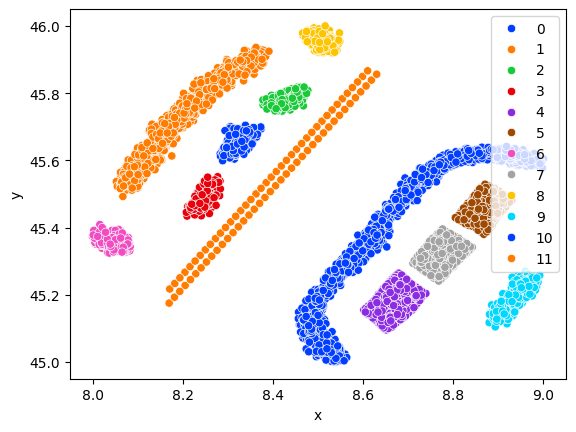

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.042)

labels = dbscan.fit_predict(df[['x', 'y']])

sns.scatterplot(x = df.x, y = df.y, hue=labels, palette='bright')
plt.show()

In [75]:
labels2 = pd.Series(labels).map(lambda x: int(x == 11))

df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df.ID,
    "answer": labels2
})

df_1.head()

,subtaskID,datapointID,answer
0,1,2472,0
1,1,4081,0
2,1,2643,0
3,1,2719,0
4,1,4975,0


In [76]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df.ID,
    "answer": labels
})

df_2.head()

,subtaskID,datapointID,answer
0,2,2472,0
1,2,4081,1
2,2,2643,2
3,2,2719,3
4,2,4975,1


In [77]:
submission = pd.concat([df_1, df_2])
submission

,subtaskID,datapointID,answer
0,1,2472,0
1,1,4081,0
2,1,2643,0
3,1,2719,0
4,1,4975,0
...,...,...,...
5018,2,2415,10
5019,2,5006,0
5020,2,2705,0
5021,2,2177,1


In [78]:
submission.answer.value_counts()

answer
0     6228
1      906
4      731
7      556
5      376
9      235
10     196
6      193
3      189
2      182
8      174
11      80
Name: count, dtype: int64

In [79]:
submission.to_csv("submission.csv", index=False)